# Does the fine-tuned model itself tell an existing behaviour from a new one?

*E50, restore on known-kind anchors, 2026-10-29. Report: `reports/analyses/2026-10-29_analysis_e50-restore-anchors.md`.*

## The answer

No, not on these toys. We put the original model's subcomponents back inside fine-tunes of known kind: copies of a
behaviour the model already has, and random maps it lacks. Both kinds gave back the same shares of their gain. All
subcomponents together took back about three quarters on both, where the plan expected a fifth or less on the random
maps. The set Γ switches on took back a tenth to a fifth on both. The all-subcomponents number may never have been able
to tell them apart, by its construction; a free check would settle that.

## What we were trying to test

The line asks whether VPD can tell a fine-tune that draws out a behaviour the model already had from one that builds
something new. So far the only number that separates the two kinds is read in Γ's stand-in model, which rebuilds the
model from its subcomponents and masks them. This experiment read a number inside the real fine-tuned model instead.

**The fine-tunes.** The 67M model and its frozen VPD decomposition. Four tables of 32 keys, each key after a marker
word. On two *copy* tables the fine-tune learns to repeat the key, which the model already does: existing by
construction. On two *random-map* tables it learns a fixed common word for each key: new by construction. Each table
was fine-tuned with two seeds, eight fine-tunes in all. The update sits outside the subcomponents, in Δ.

**The reading.** The gain is how much the answer's log-odds rose at the key position, 13 to 21 nats here. To
*restore* a set of subcomponents, each one is made to read the input it would have read in the original model, at the
key position only. Its restore share is the fraction of the gain this takes back: 0 means the set carries none of the
gain, 1 means all of it.

**The sets.**
- *Every alive subcomponent*, 9,881 of them. The plan's main reading.
- *S*, the set Γ switches on: subcomponents whose importance at the key position rises by more than 0.3.
- *Gold*: the same count of subcomponents most on before the answer words in the original model's text.
- *D*: the same count ranked by their pull on the answer, which needs the answer but not Γ.
- *Random sets*: 20 sets of S's size, the null. They rule out that any set this big takes back as much.

**The controls, run first.** Restoring any set inside the original model must change nothing, and did, exactly. Setting
every matrix's whole output at the key position back to the original's must take back all the gain, and did, exactly.

## What we expected, and why

Copying exists in the original model, so its subcomponents should carry most of a copy's gain: at least half for every
alive subcomponent, at least a fifth for S. A random map links keys to words the model never linked, so its gain was
expected in the update's own write: at most a fifth for every alive subcomponent, nearly nothing for S. The scored rule
asked for a gap of 0.3 between the worst copy and the worst random map, on both seeds. The lean was that every alive
subcomponent would show that gap.

In [1]:
import json
import runpy
from pathlib import Path

from IPython.display import Image, Markdown, display

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
EXP = ROOT / "experiments" / "restore_anchors"
R = json.loads((EXP / "results" / "restore_anchors.json").read_text())
runpy.run_path(str(EXP / "plot.py"), run_name="__main__")
print("controls passed:", R["controls_pass"], "| filed reading:", R["reading"])

controls passed: True | filed reading: does not separate


## Do the original subcomponents carry more of a copy's gain than a random map's?

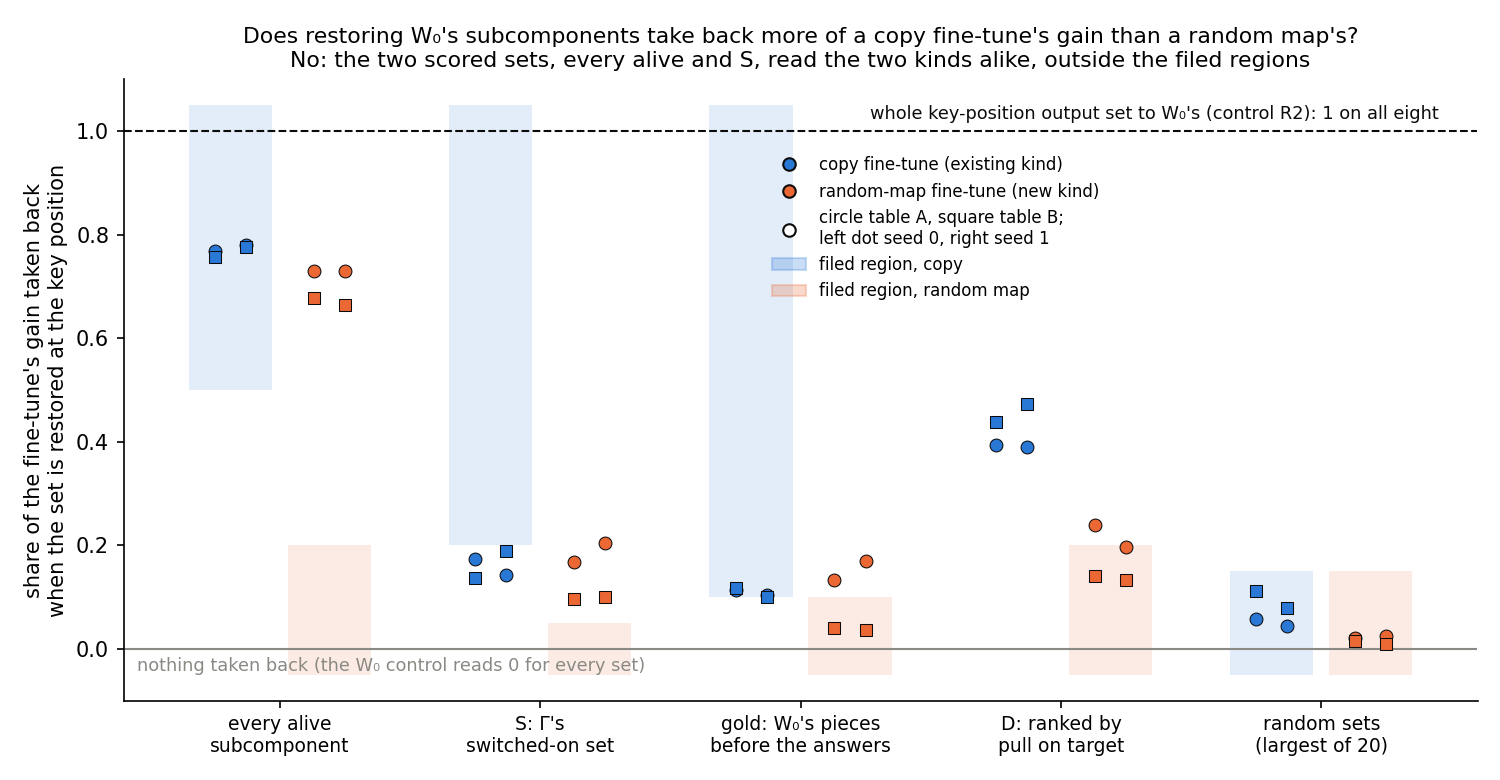

In [2]:
display(Image(filename=str(EXP / "figures" / "shares.png")))

**Reading it.** No. Every alive subcomponent took back 0.76 to 0.78 of the gain on the copies, blue, and 0.66
to 0.73 on the random maps, orange. The orange points sit far above the shaded region filed for them. S took back a tenth
to a fifth on both kinds, under the copy region and above the random-map region. The rule's gap between kinds was at
most 0.05 against a bar of 0.3, so the kinds do not separate. The random sets stay near the zero line, so S's share is
not something any set its size would show. D keeps the kinds further apart than S, but it was filed as reported only.

In [3]:
rows = ["| fine-tune | gain, nats | every alive | S | random max |", "|---|---|---|---|---|"]
names = {"ident32": "copy A", "ident32b": "copy B", "rand32": "random map A", "rand32b": "random map B"}
for key, st in R["states"].items():
    t, s = key.split("/")
    rows.append(f"| {names[t]}, seed {s[1]} | {st['gain']:.1f} | {st['rho']['every_alive']:.2f} | "
                f"{st['rho']['S']:.2f} | {st['random_max']:.2f} |")
display(Markdown("\n".join(rows)))

| fine-tune | gain, nats | every alive | S | random max |
|---|---|---|---|---|
| copy A, seed 0 | 14.0 | 0.77 | 0.17 | 0.06 |
| copy A, seed 1 | 14.1 | 0.78 | 0.14 | 0.04 |
| copy B, seed 0 | 14.6 | 0.76 | 0.14 | 0.11 |
| copy B, seed 1 | 14.3 | 0.78 | 0.19 | 0.08 |
| random map A, seed 0 | 13.7 | 0.73 | 0.17 | 0.02 |
| random map A, seed 1 | 13.2 | 0.73 | 0.20 | 0.03 |
| random map B, seed 0 | 20.7 | 0.68 | 0.10 | 0.02 |
| random map B, seed 1 | 20.6 | 0.66 | 0.10 | 0.01 |

## Could the all-subcomponents number have told them apart?

Probably not, and the reason is algebra. Each matrix is the alive subcomponents plus a leftover, Δ. Restoring every
alive subcomponent leaves only Δ's output changed. Under this placement Δ holds the update's own write. So the reading
equals the whole-output control with the update's own write switched back on. Both undo everything the original
weights do with what the update wrote: later layers reading an earlier layer's write, and attention bringing in changes
from other positions. So the share mostly measures how much of an update the original weights relay, for any update.
The random maps' early writes are turned into the answer by later original weights, so they read high.

This is a candidate, not a finding. It holds exactly only if the original model's own Δ contributes little, which was
not measured here. A free check would settle it: replace each matrix's output by the original output plus the update's
own write, with no subcomponents at all. If that reads within 0.02 of every alive subcomponent on all eight fine-tunes,
the number never depended on the decomposition.

S is different. It depends on Γ, and it beat random sets on every fine-tune, so it can see something. What it saw is
that both kinds lean on the original subcomponents by about the same amount. A candidate reading, untested: the random
maps' answers are common words, and the fine-tune reuses the original machinery for producing them. The gold set
supports this on random map A, where it took back as much as on the copies.

## What we learned

No restore share read inside the fine-tuned model told an existing behaviour from a new one on E12's toys. Under the
plan's filed branch, the line's claim about the real model is off on the 67M, and the stand-in ratio is the only number
that still separates the kinds. That ratio lives in Γ's stand-in, and an earlier check found it adds little beyond Γ's
own gain. For the project's question this fits both "No, the anchors look alike in the real model" and "Undecidable
with VPD": a new association built from existing output pieces looks like existing machinery to VPD. This run cannot
tell those two apart.

**The method's standing limit.** A new mechanism built from subcomponents the original model already has, put together
under new gating, reads as "elicited" to VPD, because its unit is the rank-one subcomponent, not the circuit. So
"elicits" from VPD means "uses pieces the original model already has", never "uses a circuit it already runs". Only a
Γ from a second decomposition seed narrows this.

## How compelling is the evidence

Two seeds and four tables, one task family, one model, one position. Seeds agreed within 0.02 on every alive
subcomponent and within 0.06 on S. The gap between kinds sat near zero, far from the bar, so this is not a threshold
case. Every alive subcomponent is blind, by construction, to anything the original weights relay. S misses subcomponents
Γ moves by 0.3 or less.

## Surprises

**Something unexpected happened.** The random maps read like the copies: every alive subcomponent took back 0.66 to 0.73
of their gain, against a filed ceiling of 0.2. This reverses the filed lean. The algebra above is a candidate
explanation; it is not yet tested. S also missed its copy floor, a fifth, on all four copy fine-tunes. And S took back
2.0 to 2.7 nats on every fine-tune, whatever its size; that is not explained.

## What next

1. The free write-only check. If it matches, the all-subcomponents share is retired as an elicitation number.
2. A decision for the user on the line's next step: carry Γ's stand-in ratio to Qwen alone, or write the elicitation
   answer as "No in the real model, undecidable at VPD's unit". The recommendation is the check first, then the
   write-up.
3. A second decomposition seed, if one exists, is the only check that narrows the method's limit.

## Scorecard

| id | claim in words | rule | read | verdict |
|---|---|---|---|---|
| reading | the kinds separate | gap ≥ 0.3 on both seeds, every alive or S | at most 0.05 | does not separate; lean reversed |
| R0-R2, C1-C2 | the restore and the readings are sound | as filed | 0 on all eight | pass |
| copy, every alive | at least 0.5 | reported | 0.76-0.78 | met |
| copy, S | at least 0.2 | reported | 0.14-0.19 | missed |
| random map, every alive | at most 0.2 | reported | 0.66-0.73 | missed |
| random map, S | at most 0.05 | reported | 0.10-0.20 | missed |
| random sets | mean ≤ 0.05, max ≤ 0.15 | reported | ≤ 0.04, ≤ 0.11 | met |

Full table with gold, D and the stand-in ratio: the report.

## Not run

- The write-only check; the all-subcomponents explanation stays a candidate until it runs.
- The all-subcomponents share on a hand-made write with no learned machinery.
- Any position but the key position; any other task family; Qwen; a second decomposition seed.

**Provenance.** Slurm 43040, MATS cluster L40, debug QoS, 78 s, $0. Results
`experiments/restore_anchors/results/restore_anchors.json`; filed rules `results/predictions.json`.